In [2]:
%pip install datasets

Defaulting to user installation because normal site-packages is not writeable
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:--
   ---------------------------------------- 608.3/608.3 kB 2.3 MB/s  0:00:00
Using cached dill-0.4.1-py3-none-any.whl (120 kB)
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ------------------------------------ --- 786.4/857.0 kB 4.1 MB/s eta 0:00:01
   ---------------------------------------- 857.0/857.0 kB 3.3 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/3.9 MB 3.9 MB/s eta 0:00:01
   -------- ------------------------------- 0.8/3.9 MB 3.6 MB/s eta 0:00:01
   -----------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import re
import random
from collections import Counter, defaultdict
from datasets import load_dataset

In [6]:
dataset = load_dataset(
    "parquet",
    data_files={
        "train": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/train-00000-of-00001.parquet",
        "test": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/test-00000-of-00001.parquet"
    }
)

print(dataset)

C:\Users\Lenovo\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating train split: 8937 examples [00:00, 74372.37 examples/s]
Generating test split: 2013 examples [00:00, 102104.63 examples/s

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 8937
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 2013
    })
})


In [7]:
all_train_data = dataset["train"]

np.random.seed(42)

indices = np.random.permutation(len(all_train_data))

split_point = int(0.8 * len(indices))

train_indices = indices[:split_point]
validation_indices = indices[split_point:]

train_data = all_train_data.select(train_indices)
validation_data = all_train_data.select(validation_indices)

test_data = dataset["test"]

print("Training sentences:", len(train_data))
print("Validation sentences:", len(validation_data))
print("Testing sentences:", len(test_data))

Training sentences: 7149
Validation sentences: 1788
Testing sentences: 2013


In [8]:
train_sentences = train_data["tokens"]
validation_sentences = validation_data["tokens"]
test_sentences = test_data["tokens"]

print(train_sentences[0])

['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']


In [9]:
def preprocess_sentence(sentence):

    processed_sentence = []

    for word in sentence:

        word = word.lower().strip()

        if word != "":
            processed_sentence.append(word)

    return processed_sentence
    

In [10]:
train_sentences = [
    preprocess_sentence(sentence)
    for sentence in train_sentences
]

validation_sentences = [
    preprocess_sentence(sentence)
    for sentence in validation_sentences
]

test_sentences = [
    preprocess_sentence(sentence)
    for sentence in test_sentences
]

In [11]:
print("Original sentence:")
print(train_data[0]["tokens"])

print("\nProcessed sentence:")
print(train_sentences[0])

Original sentence:
['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']

Processed sentence:
['one', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']


In [12]:
word_counts = Counter()

for sentence in train_sentences:

    for word in sentence:

        word_counts[word] += 1

print(word_counts.most_common(20))

[('the', 8630), (',', 8573), ('.', 6976), ('of', 4178), ('to', 4093), ('a', 3616), ('in', 3009), ('and', 2976), ('for', 1625), ("'s", 1566), ('that', 1540), ('$', 1377), ('``', 1195), ("''", 1175), ('is', 1162), ('%', 964), ('it', 962), ('said', 957), ('on', 950), ('at', 849)]


In [13]:
min_count = 2

vocabulary = []

for word, count in word_counts.items():

    if count >= min_count:
        vocabulary.append(word)

In [14]:
word_to_id = {}

for i, word in enumerate(vocabulary):

    word_to_id[word] = i


id_to_word = {}

for word, i in word_to_id.items():

    id_to_word[i] = word

print("Vocabulary size:", len(vocabulary))

print("First 20 words:", vocabulary[:20])

print("Word ID:", word_to_id.get("market"))

print("Word:", id_to_word.get(10))

Vocabulary size: 7878
First 20 words: ['one', 'of', 'the', 'advantages', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'steel', 'to', 'be', 'covered', 'with', 'a', 'more', 'quickly', '.', 'a.m']
Word ID: 177
Word: steel


In [15]:
window_size = 2

co_occurrence = defaultdict(Counter)

for sentence in train_sentences:

    for i in range(len(sentence)):

        center_word = sentence[i]

        if center_word not in word_to_id:
            continue

        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)

        for j in range(start, end):

            if i == j:
                continue

            context_word = sentence[j]

            if context_word not in word_to_id:
                continue

            co_occurrence[center_word][context_word] += 1
print(co_occurrence["market"])

Counter({'the': 182, ',': 79, '.': 50, 'stock': 49, 'a': 31, "'s": 28, 'to': 19, 'and': 18, 'is': 17, 'of': 16, 'for': 16, 'in': 15, "''": 15, 'as': 10, 'money': 8, 'by': 8, 'at': 8, 'that': 8, 'with': 8, 'said': 8, 'share': 7, 'on': 7, 'makers': 7, 'order': 7, 'will': 7, 'from': 7, 'conditions': 6, ':': 6, 'has': 6, 'value': 6, 'if': 5, 'moves': 5, 'participants': 5, 'plunge': 5, '``': 5, 'was': 5, 'bond': 5, 'index': 5, 'price': 5, 'its': 5, 'this': 5, 'u.s.': 5, 'are': 4, 'gyrations': 4, 'open': 4, '-lrb-': 4, 'when': 4, 'crash': 4, 'during': 4, 'after': 4, 'junk-bond': 4, 'funds': 4, 'friday': 4, '--': 4, 'it': 3, 'tokyo': 3, 'or': 3, 'also': 3, '1987': 3, 'secondary': 3, 'major': 3, 'into': 3, 'nervous': 3, 'out': 3, 'european': 3, 'commentary': 3, 'activity': 3, 'through': 3, 'asset-backed': 2, 'two': 2, 'silver': 2, 'london': 2, 'real-estate': 2, ';': 2, 'orders': 2, 'junk': 2, 'since': 2, 'volatility': 2, 'dominated': 2, 'which': 2, 'drop': 2, 'york': 2, 'over-the-counter': 2, 

In [16]:
total_count = 0

row_counts = Counter()
column_counts = Counter()

for word in co_occurrence:

    for context_word in co_occurrence[word]:

        count = co_occurrence[word][context_word]

        total_count += count

        row_counts[word] += count

        column_counts[context_word] += count
        

In [17]:
ppmi_matrix = defaultdict(dict)

for word in co_occurrence:

    for context_word in co_occurrence[word]:

        count = co_occurrence[word][context_word]

        pmi = np.log(
            (count * total_count) /
            (row_counts[word] * column_counts[context_word])
        )

        ppmi = max(pmi, 0)

        if ppmi > 0:

            ppmi_matrix[word][context_word] = ppmi

print("PPMI values for market:")
print(ppmi_matrix["market"])

PPMI values for market:
{'if': np.float64(1.106380227463686), 'conditions': np.float64(3.8704582600355586), 'a': np.float64(0.10422296999773094), 'late': np.float64(0.7626086883608614), 'rally': np.float64(2.4426641680089154), 'erased': np.float64(3.7583409619148527), 'the': np.float64(1.0316510458933774), 'stock': np.float64(3.1423032565123856), 'plunged': np.float64(3.0207420187840732), ',': np.float64(0.1578652125579109), 'money': np.float64(2.1286548886508045), "'s": np.float64(0.8082787251940499), 'high': np.float64(0.4625040959105234), 'for': np.float64(0.23198043729869117), 'share': np.float64(1.0686398994808388), 'by': np.float64(0.23835095339496135), 'gyrations': np.float64(4.364476765485168), 'moves': np.float64(3.776690100583049), 'japanese': np.float64(1.446706033400889), 'asset-backed': np.float64(2.5186500749868372), '.': np.float64(0.568762882457405), 'analyst': np.float64(1.1864229351372224), 'at': np.float64(0.21968996536582175), 'plans': np.float64(0.5765064087270008)

In [18]:
def sparse_cosine(vector1, vector2):

    common_words = set(vector1.keys()) & set(vector2.keys())

    dot_product = 0

    for word in common_words:

        dot_product += vector1[word] * vector2[word]

    norm1 = np.sqrt(sum(value ** 2 for value in vector1.values()))

    norm2 = np.sqrt(sum(value ** 2 for value in vector2.values()))

    if norm1 == 0 or norm2 == 0:
        return 0

    return dot_product / (norm1 * norm2)

print(sparse_cosine(
    ppmi_matrix["market"],
    ppmi_matrix["company"]
))


0.050524370963649264


In [19]:
document_frequency = Counter()

term_frequency = defaultdict(dict)

for doc_id, sentence in enumerate(train_sentences):

    word_counts_in_sentence = Counter(sentence)

    for word, count in word_counts_in_sentence.items():

        if word in word_to_id:

            term_frequency[word][doc_id] = count

            document_frequency[word] += 1

In [20]:
number_of_documents = len(train_sentences)

idf = {}

for word in vocabulary:

    df = document_frequency[word]

    idf[word] = np.log(
        (number_of_documents + 1) / (df + 1)) + 1

print("IDF of market:", idf.get("market"))
print("IDF of the:", idf.get("the"))

IDF of market: 4.167757370939178
IDF of the: 1.4058148195997509


In [21]:
tfidf_vectors = defaultdict(dict)

for word in term_frequency:

    for doc_id, count in term_frequency[word].items():

        tf = count

        tfidf = tf * idf[word]

        tfidf_vectors[word][doc_id] = tfidf

print(tfidf_vectors["market"])

{15: np.float64(4.167757370939178), 50: np.float64(4.167757370939178), 71: np.float64(4.167757370939178), 130: np.float64(4.167757370939178), 136: np.float64(4.167757370939178), 151: np.float64(4.167757370939178), 160: np.float64(4.167757370939178), 186: np.float64(4.167757370939178), 206: np.float64(4.167757370939178), 217: np.float64(4.167757370939178), 223: np.float64(4.167757370939178), 231: np.float64(4.167757370939178), 238: np.float64(4.167757370939178), 256: np.float64(8.335514741878356), 272: np.float64(4.167757370939178), 274: np.float64(4.167757370939178), 332: np.float64(4.167757370939178), 417: np.float64(4.167757370939178), 430: np.float64(4.167757370939178), 438: np.float64(4.167757370939178), 451: np.float64(4.167757370939178), 529: np.float64(4.167757370939178), 541: np.float64(4.167757370939178), 555: np.float64(8.335514741878356), 556: np.float64(4.167757370939178), 636: np.float64(4.167757370939178), 676: np.float64(4.167757370939178), 677: np.float64(4.167757370939

In [22]:
similarity = sparse_cosine(
    tfidf_vectors["market"],
    tfidf_vectors["company"]
)

print("TF-IDF similarity:", similarity)

TF-IDF similarity: 0.037927046377141165


In [23]:
train_sentences_ids = []

for sentence in train_sentences:

    sentence_ids = []

    for word in sentence:

        if word in word_to_id:

            sentence_ids.append(word_to_id[word])

    train_sentences_ids.append(sentence_ids)
print(train_sentences[0])
print(train_sentences_ids[0])


['one', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']
[0, 1, 2, 3, 1, 2, 4, 5, 6, 7, 8, 9, 2, 10, 11, 12, 13, 14, 15, 1, 16, 17, 18]


In [24]:
window_size = 2

training_pairs = []

for sentence in train_sentences_ids:

    for i in range(len(sentence)):

        center_word = sentence[i]

        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)

        for j in range(start, end):

            if i != j:

                context_word = sentence[j]

                training_pairs.append(
                    (center_word, context_word)
                )

In [25]:
print("Number of training pairs:", len(training_pairs))

print("First 10 pairs:")

for pair in training_pairs[:10]:

    print(
        id_to_word[pair[0]],
        "->",
        id_to_word[pair[1]]
    )

Number of training pairs: 605050
First 10 pairs:
one -> of
one -> the
of -> one
of -> the
of -> advantages
the -> one
the -> of
the -> advantages
the -> of
advantages -> of


In [26]:
vocab_size = len(vocabulary)

embedding_dim = 50

negative_samples = 5

learning_rate = 0.025

epochs = 3

np.random.seed(42)

input_embeddings = np.random.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

In [27]:
word_frequencies = np.zeros(vocab_size)

for word, word_id in word_to_id.items():

    word_frequencies[word_id] = word_counts[word]


negative_distribution = word_frequencies ** 0.75

negative_distribution = (
    negative_distribution / np.sum(negative_distribution)
)

In [28]:
def sigmoid(x):

    x = np.clip(x, -15, 15)

    return 1 / (1 + np.exp(-x))

In [29]:
def calculate_loss(center_id, context_id):

    center_vector = input_embeddings[center_id]

    positive_vector = output_embeddings[context_id]

    positive_score = np.dot(center_vector, positive_vector)

    positive_loss = np.logaddexp(0, -positive_score)

    negative_ids = []

    for i in range(negative_samples):

        negative_id = np.random.choice(
            vocab_size,
            p=negative_distribution
        )

        while negative_id == context_id:

            negative_id = np.random.choice(
                vocab_size,
                p=negative_distribution
            )

        negative_ids.append(negative_id)

    negative_vectors = output_embeddings[negative_ids]

    negative_scores = np.dot(
        negative_vectors,
        center_vector
    )

    negative_loss = np.sum(
        np.logaddexp(0, negative_scores)
    )

    total_loss = positive_loss + negative_loss

    return total_loss, negative_ids

In [30]:
def train_pair(center_id, context_id):

    global input_embeddings
    global output_embeddings

    center_vector = input_embeddings[center_id].copy()

    positive_vector = output_embeddings[context_id].copy()

    positive_score = np.dot(center_vector, positive_vector)

    negative_ids = []

    for i in range(negative_samples):

        negative_id = np.random.choice(
            vocab_size,
            p=negative_distribution
        )

        while negative_id == context_id:

            negative_id = np.random.choice(
                vocab_size,
                p=negative_distribution
            )

        negative_ids.append(negative_id)

    negative_vectors = output_embeddings[negative_ids].copy()

    negative_scores = np.dot(
        negative_vectors,
        center_vector
    )

    # Calculate loss

    loss = np.logaddexp(0, -positive_score)

    loss += np.sum(np.logaddexp(0, negative_scores))

    # Calculate gradients

    positive_gradient = sigmoid(positive_score) - 1

    negative_gradients = sigmoid(negative_scores)

    center_gradient = (
        positive_gradient * positive_vector
        +
        np.sum(
            negative_gradients[:, None] * negative_vectors,
            axis=0
        )
    )

    positive_output_gradient = positive_gradient * center_vector

    negative_output_gradients = (
        negative_gradients[:, None] * center_vector
    )

    # Update input embedding

    input_embeddings[center_id] -= (
        learning_rate * center_gradient
    )

    # Update positive output embedding

    output_embeddings[context_id] -= (
        learning_rate * positive_output_gradient
    )

    # Update negative output embeddings

    np.add.at(
        output_embeddings,
        negative_ids,
        -learning_rate * negative_output_gradients
    )

    return loss

In [33]:

epoch_losses = []

# Faster training settings
min_delta = 0.001
patience = 2

best_loss = float("inf")
epochs_without_improvement = 0

# Use a smaller training subset for faster experimentation
max_pairs = 20000

# Make a copy so the original training pairs remain unchanged
fast_training_pairs = training_pairs[:max_pairs]

print("Training pairs:", len(fast_training_pairs))

for epoch in range(epochs):

    random.shuffle(fast_training_pairs)

    total_loss = 0

    for center_id, context_id in fast_training_pairs:

        loss = train_pair(center_id, context_id)
        total_loss += loss

    average_loss = total_loss / len(fast_training_pairs)
    epoch_losses.append(average_loss)

    print(f"Epoch {epoch + 1}: Loss = {average_loss:.4f}")

    # Early stopping
    if best_loss - average_loss > min_delta:

        best_loss = average_loss
        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping triggered!")
        break

print("Training finished.")
print("Total epochs:", len(epoch_losses))
print("Best loss:", best_loss)

# Save the learned embeddings
word2vec_embeddings = input_embeddings.copy()


Training pairs: 20000
Epoch 1: Loss = 2.5570
Epoch 2: Loss = 2.4753
Epoch 3: Loss = 2.4064
Training finished.
Total epochs: 3
Best loss: 2.4064278473151304


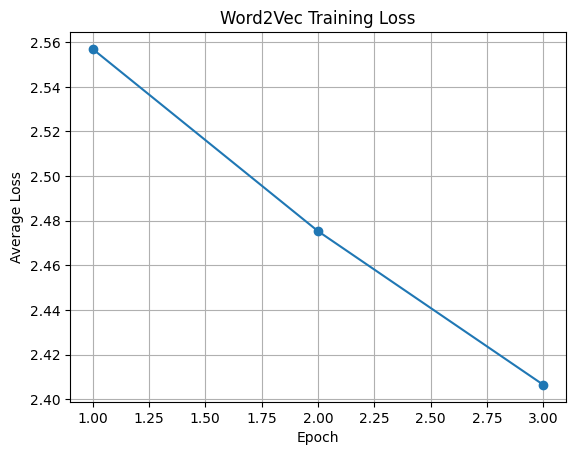

In [34]:
import matplotlib.pyplot as plt

plt.plot(range(1, epochs + 1), epoch_losses, marker="o")

plt.xlabel("Epoch")

plt.ylabel("Average Loss")

plt.title("Word2Vec Training Loss")

plt.grid()

plt.show()

In [35]:
word2vec_embeddings = input_embeddings.copy()
print("Embedding matrix shape:", word2vec_embeddings.shape)

print("Embedding of market:")

print(
    word2vec_embeddings[word_to_id["market"]]
)

Embedding matrix shape: (7878, 50)
Embedding of market:
[-0.28522817  0.46467343 -0.40508012  0.41981423  0.32609247 -0.22528316
 -0.12418357 -0.21075874 -0.31289723  0.00676008 -0.56143915 -0.78359222
  0.57910729  0.1852091  -0.42452491  0.84406804 -0.38530798  0.15662954
  0.49370227  0.0272694   0.04187422 -0.21847778 -0.53571107 -0.04170497
  0.2933397  -0.3312      0.29910075  0.58780423  0.13501782 -0.26945496
 -0.15853918  0.23997281 -0.38701913  0.00152755 -0.08225588  0.11512503
 -0.339453    0.02263273  0.18874637  0.42831277  0.11231432  0.64560176
  0.47650685 -0.33767578 -0.35702791 -0.12118103 -0.29098981 -0.38332583
  0.09867605 -0.42692484]


In [36]:
def find_sparse_neighbors(query_word, vectors, top_n=5):

    if query_word not in vectors:
        return []

    similarities = []

    query_vector = vectors[query_word]

    for word in vectors:

        if word == query_word:
            continue

        similarity = sparse_cosine(
            query_vector,
            vectors[word]
        )

        similarities.append((word, similarity))

    similarities.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return similarities[:top_n]

In [37]:
def dense_cosine(vector1, vector2):

    dot_product = np.dot(vector1, vector2)

    norm1 = np.linalg.norm(vector1)

    norm2 = np.linalg.norm(vector2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return dot_product / (norm1 * norm2)

In [38]:
def find_word2vec_neighbors(query_word, top_n=5):

    if query_word not in word_to_id:
        return []

    query_id = word_to_id[query_word]

    query_vector = word2vec_embeddings[query_id]

    similarities = []

    for word, word_id in word_to_id.items():

        if word == query_word:
            continue

        similarity = dense_cosine(
            query_vector,
            word2vec_embeddings[word_id]
        )

        similarities.append((word, similarity))

    similarities.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return similarities[:top_n]

In [39]:
query_words = ["market", "government", "company", "people"]
for word in query_words:

    if word not in word_to_id:

        print(word, "is not in the vocabulary")
for word in query_words:

    print("\n==============================")

    print("QUERY WORD:", word)

    print("\nPMI Neighbors:")

    print(find_sparse_neighbors(
        word,
        ppmi_matrix
    ))

    print("\nTF-IDF Neighbors:")

    print(find_sparse_neighbors(
        word,
        tfidf_vectors
    ))

    print("\nWord2Vec Neighbors:")

    print(find_word2vec_neighbors(word))


QUERY WORD: market

PMI Neighbors:
[('stock', np.float64(0.15908079325522917)), ('plunge', np.float64(0.13728940837722298)), ('stock-market', np.float64(0.1301297900970848)), ('participants', np.float64(0.1194139782721437)), ('arena', np.float64(0.11842057912495638))]

TF-IDF Neighbors:
[('the', np.float64(0.21692674197862824)), ('.', np.float64(0.194870376790154)), ('makers', np.float64(0.1919954293673661)), ('stock', np.float64(0.18922873030731946)), (',', np.float64(0.15143957422759052))]

Word2Vec Neighbors:
[('firm', np.float64(0.9512739357224016)), ('spokesman', np.float64(0.9481772159636371)), ('computer', np.float64(0.9481000800660673)), ('bank', np.float64(0.9405122840625659)), ('bureau', np.float64(0.9382058635040116))]

QUERY WORD: government

PMI Neighbors:
[('harshly', np.float64(0.10789840604700633)), ('bureaucracy', np.float64(0.09789323633872617)), ('fields', np.float64(0.09450763275094036)), ('tuitions', np.float64(0.09060894182393985)), ('californians', np.float64(0.

In [40]:
vocab_size = len(vocabulary)

number_of_documents = len(train_sentences)

# PMI

pmi_nonzero = sum(
    len(row)
    for row in ppmi_matrix.values()
)

pmi_dimensions = (vocab_size, vocab_size)


# TF-IDF

tfidf_nonzero = sum(
    len(row)
    for row in tfidf_vectors.values()
)

tfidf_dimensions = (vocab_size, number_of_documents)


# Word2Vec

word2vec_nonzero = np.count_nonzero(word2vec_embeddings)

word2vec_dimensions = word2vec_embeddings.shape

In [41]:
pmi_density = pmi_nonzero / (
    vocab_size * vocab_size
)

tfidf_density = tfidf_nonzero / (
    vocab_size * number_of_documents
)

word2vec_density = word2vec_nonzero / (
    vocab_size * embedding_dim
)

In [42]:
print("PMI")
print("Dimensions:", pmi_dimensions)
print("Nonzero values:", pmi_nonzero)
print("Density:", pmi_density)

print("\nTF-IDF")
print("Dimensions:", tfidf_dimensions)
print("Nonzero values:", tfidf_nonzero)
print("Density:", tfidf_density)

print("\nWord2Vec")
print("Dimensions:", word2vec_dimensions)
print("Nonzero values:", word2vec_nonzero)
print("Density:", word2vec_density)

PMI
Dimensions: (7878, 7878)
Nonzero values: 239820
Density: 0.003864145275620772

TF-IDF
Dimensions: (7878, 7149)
Nonzero values: 143646
Density: 0.0025505407314675107

Word2Vec
Dimensions: (7878, 50)
Nonzero values: 393900
Density: 1.0
